Fichier chargé : C:\Users\Lenovo-YOGA/Downloads\africa.gml

RÉSEAU AFRICAIN
Routeurs                : 403
Liens (non orientés)    : 536
Liens orientés          : 1072
Réseau connexe          : True
Composantes connexes    : 1
Demande de référence    : 6272 -> 6266, 20.0 Mb/s
Capacités et délais     : données simulées (le fichier n'en contient pas)

EXPÉRIENCE DE CHARGE (le trafic augmente)
          methode  parametre         L      U  latence_moyenne  nb_liens_depasses
plus court chemin        0.5  227.2000 0.1253          22.7200                  0
          latence        0.5  227.2000 0.1253          22.7200                  0
       congestion        0.5  500.9333 0.0729          50.0933                  0
plus court chemin        1.0  454.4000 0.2505          22.7200                  0
          latence        1.0  454.4000 0.2505          22.7200                  0
       congestion        1.0 1001.8665 0.1457          50.0933                  0
plus court chemin        1.5  681

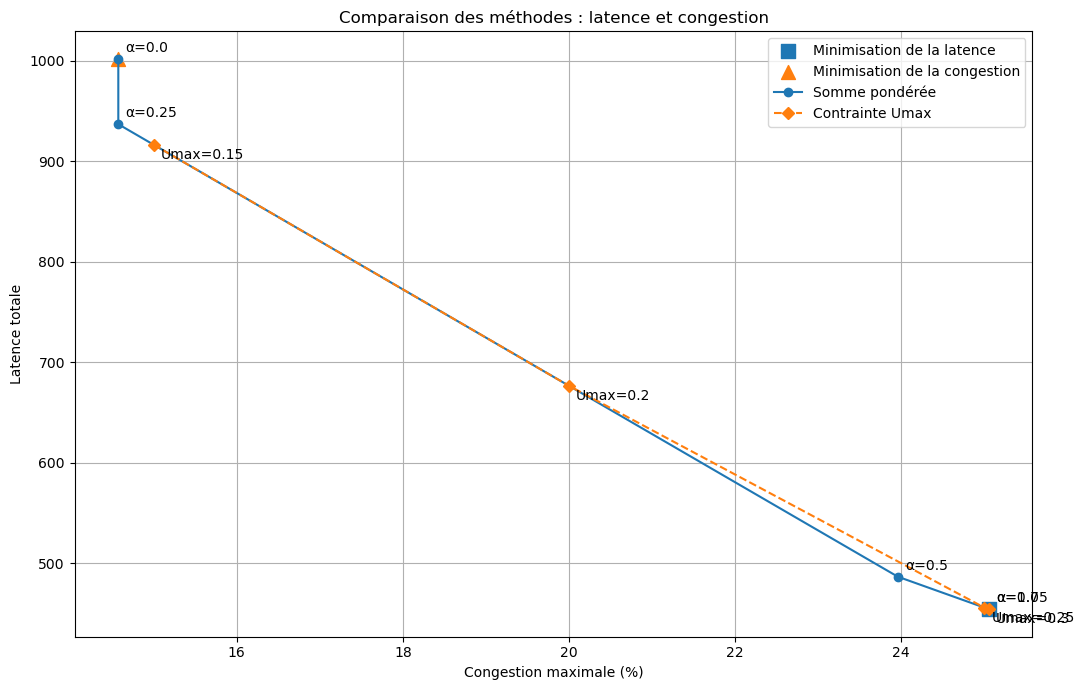

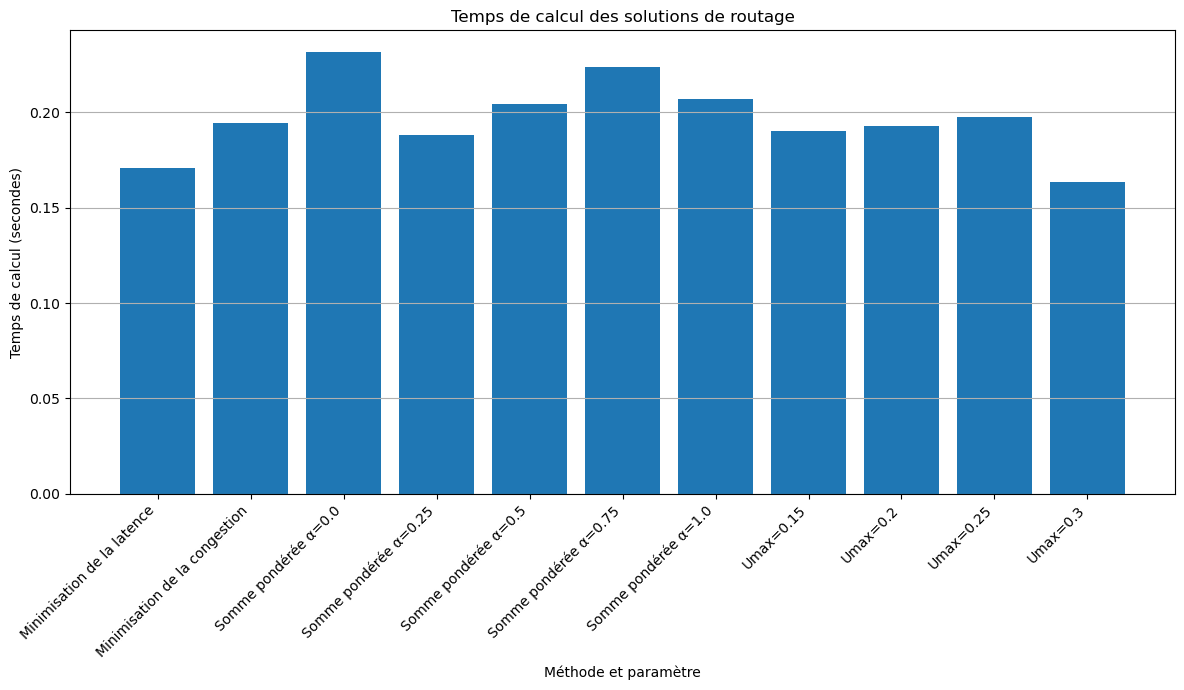


ROUTAGE PERSONNALISÉ
Le graphe contient 403 routeurs.
Tu peux saisir un identifiant ou parcourir la liste.



Identifiant source (ou tape LISTE pour parcourir) :  2

Identifiant destination (ou tape LISTE pour parcourir) :  1445


Identifiant introuvable. Essaie LISTE pour parcourir.



Identifiant destination (ou tape LISTE pour parcourir) :  1410


Identifiant introuvable. Essaie LISTE pour parcourir.



Identifiant destination (ou tape LISTE pour parcourir) :  5
Volume demandé (Mb/s) :  80



Choisis la méthode de routage :
1 - Minimiser la latence
2 - Minimiser la congestion
3 - Somme pondérée
4 - Contrainte sur Umax


Choix (1, 2, 3 ou 4) :  4
Umax entre 0 et 1 :  0.3



Statut de la solution : Infeasible
Aucune solution optimale n'a été trouvée.
Essaie un volume inférieur ou un autre seuil Umax.


In [5]:
#!/usr/bin/env python3
"""
Routage optimal dans un réseau de routeurs (projet de RO : Télécommunications et Réseaux).

Le programme :
  1. charge le réseau africain (africa.gml) et en fait une Instance ;
  2. étudie l'effet de la charge et de la taille du réseau ;
  3. compare quatre méthodes (latence, congestion, somme pondérée, contrainte Umax) ;
  4. propose un routage personnalisé (choix du routeur source, destination, volume, méthode).

Utilisation :
    python routage_africa.py                          # cherche africa.gml automatiquement
    python routage_africa.py --gml chemin/africa.gml  # fichier indiqué à la main
    python routage_africa.py --sans-experiences       # saute les expériences de charge et de taille
    python routage_africa.py --sans-interactif        # saute le routage personnalisé (pas de saisie)

Dépendances :  pip install "pulp<4" networkx pandas matplotlib   (PuLP 4 a changé son API)
"""

import argparse
import copy
import heapq
import os
import random
import sys
import time
import warnings
from collections import deque
from dataclasses import dataclass, replace

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from pulp import LpProblem, LpVariable, LpMinimize, LpStatus, PULP_CBC_CMD, lpSum, value

warnings.filterwarnings("ignore", category=DeprecationWarning)  # messages de PuLP sans importance
warnings.filterwarnings("ignore", category=FutureWarning)  # messages de pandas sans importance

# Évite les erreurs d'affichage (→, α, ×) dans la console Windows.
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")


# =============================================================================
#  PARTIE 1 — BIBLIOTHÈQUE DU PROJET (groupes G1 à G5)
# =============================================================================


@dataclass
class Instance:
    """
    FORMAT 1 : l'instance (les données du problème).
      N            : liste des routeurs, par exemple ["A", "B", "C", "D"]
      A            : liste des liens orientés, par exemple [("A", "B"), ("B", "D")]
                     (un lien aller et un lien retour comptent pour deux)
      c            : capacité de chaque lien, en Mb/s       {("A", "B"): 8.0, ...}
      d            : délai de chaque lien, en ms            {("A", "B"): 2.0, ...}
      demandes     : liste de (départ, arrivée, volume en Mb/s)
      K            : numéros des demandes [0, 1, ...]
      volume_total : somme des volumes (sert à calculer la latence moyenne)
    """

    N: list
    A: list
    c: dict
    d: dict
    demandes: list
    K: list
    volume_total: float


def creer_instance_routage():
    """
    LÉGENDE
      Groupe  : G1
      Rôle    : écrit à la main le petit réseau de l'exemple A→D. On connaît déjà la bonne
                réponse, donc il sert à tester tout le reste.
      Entrée  : aucune.
      Sortie  : une Instance (4 routeurs, 4 liens de 8 Mb/s, 1 demande de 10 Mb/s de A vers D).
                Délais : A→B 2 ms, B→D 2 ms, A→C 5 ms, C→D 5 ms.
    """
    liens = [("A", "B"), ("B", "D"), ("A", "C"), ("C", "D")]
    return Instance(
        N=["A", "B", "C", "D"],
        A=liens,
        c={a: 8.0 for a in liens},
        d={("A", "B"): 2.0, ("B", "D"): 2.0, ("A", "C"): 5.0, ("C", "D"): 5.0},
        demandes=[("A", "D", 10.0)],
        K=[0],
        volume_total=10.0,
    )


def mesurer_temps(fonction, *args, **kwargs):
    """
    LÉGENDE
      Groupe  : G5
      Rôle    : chronomètre un calcul.
      Entrées : fonction (la fonction à appeler) ; *args, **kwargs (ses arguments).
      Sortie  : le couple (résultat de la fonction, durée en secondes).
    """
    debut = time.perf_counter()
    resultat = fonction(*args, **kwargs)
    duree = time.perf_counter() - debut
    return resultat, duree


def verifier_statut(statut):
    """
    LÉGENDE
      Groupe  : G4
      Rôle    : arrête le programme si le solveur n'a pas trouvé la meilleure solution.
      Entrée  : statut (texte renvoyé par le solveur : « Optimal », « Infeasible »...).
      Sortie  : rien si le statut est « Optimal » ; sinon une erreur (RuntimeError).
    """
    if statut != "Optimal":
        raise RuntimeError(f"Le solveur n'a pas trouvé de solution optimale (statut : {statut}).")


def evaluer_routage(inst, flots):
    """
    LÉGENDE
      Groupe  : G4
      Rôle    : juge une solution, d'où qu'elle vienne.
      Entrées : inst (Instance) ; flots (FORMAT 2 : {(k, (i, j)): trafic en Mb/s}).
      Sortie  : dictionnaire de mesures :
                L                 latence totale (ms x Mb/s)
                latence_moyenne   L / volume total, en ms
                U                 taux du lien le plus chargé (sans unité)
                nb_liens_80       nombre de liens chargés à 80 % ou plus
                nb_liens_depasses nombre de liens au-dessus de leur capacité
                valide            True si le trafic est bien conservé à chaque routeur
    """
    charge = {a: sum(flots[k, a] for k in inst.K) for a in inst.A}
    taux = {a: charge[a] / inst.c[a] for a in inst.A}
    L = sum(inst.d[a] * charge[a] for a in inst.A)

    valide = True
    for k, (depart, arrivee, volume) in enumerate(inst.demandes):
        for i in inst.N:
            sortie = sum(flots[k, a] for a in inst.A if a[0] == i)
            entree = sum(flots[k, a] for a in inst.A if a[1] == i)
            attendu = volume if i == depart else (-volume if i == arrivee else 0)
            if abs(sortie - entree - attendu) > 1e-6:
                valide = False

    return {
        "L": L,
        "latence_moyenne": L / inst.volume_total,
        "U": max(taux.values()),
        "nb_liens_80": sum(t >= 0.8 - 1e-9 for t in taux.values()),
        "nb_liens_depasses": sum(t > 1 + 1e-9 for t in taux.values()),
        "valide": valide,
    }


def _plus_court(inst, depart, arrivee):
    """Algorithme de Dijkstra sur les délais : renvoie la liste des routeurs du chemin."""
    voisins = {n: [] for n in inst.N}
    for i, j in inst.A:
        voisins[i].append(j)
    distance = {n: float("inf") for n in inst.N}
    distance[depart] = 0.0
    precedent = {}
    file = [(0.0, depart)]
    while file:
        dist_u, u = heapq.heappop(file)
        if dist_u > distance[u]:
            continue
        if u == arrivee:
            break
        for v in voisins[u]:
            nouvelle = dist_u + inst.d[(u, v)]
            if nouvelle < distance[v]:
                distance[v] = nouvelle
                precedent[v] = u
                heapq.heappush(file, (nouvelle, v))
    if arrivee != depart and arrivee not in precedent:
        raise ValueError(f"Aucun chemin de {depart} vers {arrivee}.")
    chemin = [arrivee]
    while chemin[-1] != depart:
        chemin.append(precedent[chemin[-1]])
    chemin.reverse()
    return chemin


def plus_court_chemin(inst):
    """
    LÉGENDE
      Groupe  : G4
      Rôle    : routage de référence SANS optimisation (l'« avant » pour mesurer le gain).
                C'est ce que fait un routeur par défaut.
      Entrée  : inst.
      Sortie  : des flots (FORMAT 2). Chaque demande envoie tout son volume sur le chemin de plus
                petit délai (Dijkstra), SANS regarder les capacités : des liens peuvent être dépassés.
    """
    flots = {(k, a): 0.0 for k in inst.K for a in inst.A}
    for k, (depart, arrivee, volume) in enumerate(inst.demandes):
        chemin = _plus_court(inst, depart, arrivee)
        for u, v in zip(chemin, chemin[1:]):
            flots[k, (u, v)] += volume
    return flots


def construire_base_routage(inst):
    """
    LÉGENDE
      Groupe  : G2
      Rôle    : écrit les règles communes à tous les objectifs : le trafic part du départ,
                traverse le réseau sans se perdre et arrive à destination.
      Entrée  : inst (Instance).
      Sortie  : le couple (prob, f) :
                prob = le problème, SANS capacités ni objectif ;
                f    = dictionnaire des variables de flot f[(k, (i, j))].
      Comment : une variable (jamais négative) par demande et par lien ; puis, pour chaque
                demande et chaque routeur : trafic qui sort - trafic qui entre
                = volume au départ, - volume à l'arrivée, 0 ailleurs.
    """
    prob = LpProblem("routage", LpMinimize)
    f = {(k, a): LpVariable(f"f_{k}_{a[0]}_{a[1]}", lowBound=0) for k in inst.K for a in inst.A}
    for k, (depart, arrivee, volume) in enumerate(inst.demandes):
        for i in inst.N:
            sortie = lpSum(f[k, a] for a in inst.A if a[0] == i)
            entree = lpSum(f[k, a] for a in inst.A if a[1] == i)
            if i == depart:
                reste = volume  # il sort `volume` de plus qu'il n'entre
            elif i == arrivee:
                reste = -volume  # il entre `volume` de plus qu'il ne sort
            else:
                reste = 0  # un routeur intermédiaire ne perd rien
            prob += sortie - entree == reste
    return prob, f


def ajouter_objectif_latence(prob, f, inst):
    """
    LÉGENDE
      Groupe  : G2
      Rôle    : ajoute la limite de capacité et le but « aller le plus vite possible ».
      Entrées : prob, f (venant de construire_base_routage) ; inst.
      Sortie  : le problème complété.
      Comment : trafic total de chaque lien <= sa capacité c ;
                on minimise la somme de (délai d x trafic f), en ms x Mb/s.
    """
    for a in inst.A:
        prob += lpSum(f[k, a] for k in inst.K) <= inst.c[a]
    prob += lpSum(inst.d[a] * f[k, a] for k in inst.K for a in inst.A)
    return prob


def resoudre_routage(prob, f):
    """
    LÉGENDE
      Groupe  : G2
      Rôle    : demande au solveur de trouver la meilleure solution.
      Entrées : prob (problème complété) ; f (dictionnaire des variables de flot).
      Sortie  : FORMAT 3 = (flots, valeur, statut, temps) :
                flots  = {(k, (i, j)): trafic en Mb/s} (FORMAT 2), ou None s'il n'y a pas de solution ;
                valeur = valeur de l'objectif, ou None ;
                statut = « Optimal » ou « Infeasible » (ou autre message du solveur) ;
                temps  = durée du solveur seul, en secondes.
    """
    _, temps = mesurer_temps(prob.solve, PULP_CBC_CMD(msg=False))
    statut = LpStatus[prob.status]
    if statut != "Optimal":
        return None, None, statut, temps
    flots = {cle: (variable.value() or 0.0) for cle, variable in f.items()}
    return flots, value(prob.objective), statut, temps


def ajouter_objectif_congestion(prob, f, inst):
    """
    LÉGENDE
      Groupe  : G3
      Rôle    : ajoute le but « ne surcharger aucun lien ».
      Entrées : prob, f (venant de construire_base_routage) ; inst.
      Sortie  : le couple (problème complété, variable U).
      Comment : U = taux d'occupation du lien le plus chargé, entre 0 et 1 ;
                trafic total de chaque lien <= U x capacité ; on minimise U.
                Comme U <= 1, aucune capacité ne peut être dépassée : si la demande est trop
                grande, le statut est « Infeasible ».
    """
    U = LpVariable("U", lowBound=0, upBound=1)
    for a in inst.A:
        prob += lpSum(f[k, a] for k in inst.K) <= U * inst.c[a]
    prob += U
    return prob, U


def resoudre_objectif(inst, objectif):
    """
    LÉGENDE
      Groupe  : G2 (utilise la fonction du G3 pour la congestion)
      Rôle    : enchaîne les trois étapes (base, objectif, résolution) pour un objectif simple.
                Évite d'oublier de reconstruire la base à chaque objectif.
      Entrées : inst ; objectif = "latence" ou "congestion".
      Sortie  : FORMAT 3 = (flots, valeur, statut, temps).
    """
    prob, f = construire_base_routage(inst)
    if objectif == "latence":
        prob = ajouter_objectif_latence(prob, f, inst)
    elif objectif == "congestion":
        prob, _ = ajouter_objectif_congestion(prob, f, inst)
    else:
        raise ValueError(f"Objectif inconnu : {objectif}")
    return resoudre_routage(prob, f)


def ligne_mesures(methode, parametre, inst, resultat):
    """
    LÉGENDE
      Groupe  : G4
      Rôle    : transforme un résultat de résolution en UNE ligne de tableau (même forme
                pour toutes les méthodes, pour pouvoir les mettre dans le même tableau).
      Entrées : methode (texte) ; parametre (alpha, U_max, coefficient de charge... ou "") ;
                inst ; resultat (FORMAT 3 : flots, valeur, statut, temps).
      Sortie  : dictionnaire avec methode, parametre, statut, temps, L, latence_moyenne, U,
                nb_liens_depasses (ces quatre dernières valent None s'il n'y a pas de solution).
    """
    flots, _, statut, temps = resultat
    ligne = {
        "methode": methode,
        "parametre": parametre,
        "statut": statut,
        "temps": temps,
        "L": None,
        "latence_moyenne": None,
        "U": None,
        "nb_liens_depasses": None,
    }
    if flots is not None:
        m = evaluer_routage(inst, flots)
        ligne.update(
            {
                "L": m["L"],
                "latence_moyenne": m["latence_moyenne"],
                "U": m["U"],
                "nb_liens_depasses": m["nb_liens_depasses"],
            }
        )
    return ligne


def _chemin_avec_trafic(reste, depart, arrivee):
    """Parcours en largeur : un chemin du départ à l'arrivée, uniquement par des liens non vides."""
    voisins = {}
    for i, j in reste:
        voisins.setdefault(i, []).append(j)
    precedent = {depart: None}
    file = deque([depart])
    while file:
        u = file.popleft()
        if u == arrivee:
            break
        for v in voisins.get(u, []):
            if v not in precedent:
                precedent[v] = u
                file.append(v)
    if arrivee not in precedent:
        return None
    chemin = [arrivee]
    while precedent[chemin[-1]] is not None:
        chemin.append(precedent[chemin[-1]])
    chemin.reverse()
    return chemin


def extraire_chemins(inst, flots, tolerance=1e-9):
    """
    LÉGENDE
      Groupe  : G4
      Rôle    : traduit les flots (trafic par lien) en chemins faciles à lire, par exemple
                « 80 % par A→B→D, 20 % par A→C→D ».
      Entrées : inst ; flots (FORMAT 2).
      Sortie  : dictionnaire {numéro de demande: liste de (chemin, quantité en Mb/s, part du volume)},
                triée de la plus grosse quantité à la plus petite.
      Comment : pour chaque demande, on cherche un chemin du départ à l'arrivée en suivant les
                liens où il passe du trafic, on note la plus petite quantité rencontrée, on la
                retire, et on recommence jusqu'à épuisement. Les petits cycles inutiles sont ignorés.
    """
    resultat = {}
    for k, (depart, arrivee, volume) in enumerate(inst.demandes):
        reste = {a: flots[k, a] for a in inst.A if flots[k, a] > tolerance}
        chemins, extrait = [], 0.0
        while extrait < volume - 1e-6:
            chemin = _chemin_avec_trafic(reste, depart, arrivee)
            if chemin is None:
                break
            liens = list(zip(chemin, chemin[1:]))
            quantite = min(reste[a] for a in liens)
            for a in liens:
                reste[a] -= quantite
                if reste[a] <= tolerance:
                    del reste[a]
            chemins.append((tuple(chemin), quantite, quantite / volume))
            extrait += quantite
        chemins.sort(key=lambda ch: -ch[1])
        resultat[k] = chemins
    return resultat


def ecart_relatif(valeur, optimum):
    """
    LÉGENDE
      Groupe  : G5
      Rôle    : dit de combien (en %) une valeur dépasse le meilleur résultat possible.
      Entrées : valeur ; optimum (le meilleur résultat possible, différent de 0).
      Sortie  : (valeur - optimum) / optimum x 100.
      Exemple : ecart_relatif(70, 52) donne environ 34,6 : la latence de 70 est 34,6 %
                au-dessus de la meilleure latence possible (52).
    """
    if optimum == 0:
        raise ValueError("L'optimum vaut 0 : l'écart relatif n'est pas défini.")
    return (valeur - optimum) / optimum * 100


def somme_ponderee_routage(inst, alpha, L_etoile, U_etoile):
    """
    LÉGENDE
      Groupe  : G5
      Rôle    : cherche un compromis entre vitesse et sécurité avec un curseur alpha.
      Entrées : inst ; alpha (entre 0 et 1) ; L_etoile ; U_etoile (les meilleures valeurs
                obtenues avec chaque objectif seul : elles mettent la latence et la congestion
                à la même échelle).
      Sortie  : FORMAT 3 = (flots, valeur, statut, temps).
      Comment : minimise  alpha x (L / L*) + (1 - alpha) x (U / U*),  avec U <= 1 et
                trafic de chaque lien <= U x capacité.
                alpha = 1 redonne la solution latence ; alpha = 0 la solution congestion.
    """
    if not 0 <= alpha <= 1:
        raise ValueError("alpha doit être compris entre 0 et 1")
    prob, f = construire_base_routage(inst)
    U = LpVariable("U", lowBound=0, upBound=1)
    for a in inst.A:
        prob += lpSum(f[k, a] for k in inst.K) <= U * inst.c[a]
    L = lpSum(inst.d[a] * f[k, a] for k in inst.K for a in inst.A)
    prob += (alpha / L_etoile) * L + ((1 - alpha) / U_etoile) * U
    return resoudre_routage(prob, f)


def contrainte_sur_critere(inst, U_max):
    """
    LÉGENDE
      Groupe  : G5 (fonction optionnelle)
      Rôle    : cherche la solution la plus rapide en s'interdisant de dépasser une charge donnée.
      Entrées : inst ; U_max (limite de charge, entre 0 et 1 ; doit être au moins égale à U*).
      Sortie  : FORMAT 3. Statut « Infeasible » si U_max est inférieur à U*.
      Comment : on minimise la latence totale, avec trafic de chaque lien <= U_max x capacité.
                Faire varier U_max donne des solutions INTERMÉDIAIRES que la somme pondérée
                ne trouve jamais.
    """
    prob, f = construire_base_routage(inst)
    for a in inst.A:
        prob += lpSum(f[k, a] for k in inst.K) <= U_max * inst.c[a]
    prob += lpSum(inst.d[a] * f[k, a] for k in inst.K for a in inst.A)
    return resoudre_routage(prob, f)


def _ligne(methode, parametre, inst, resultat, L_etoile, U_etoile):
    """Une ligne de tableau : les mesures (groupe 4) + les écarts à L* et U* en %."""
    ligne = ligne_mesures(methode, parametre, inst, resultat)
    ligne["ecart_L_pct"] = None
    ligne["ecart_U_pct"] = None
    if ligne["L"] is not None:
        ligne["ecart_L_pct"] = ecart_relatif(ligne["L"], L_etoile)
        ligne["ecart_U_pct"] = ecart_relatif(ligne["U"], U_etoile)
    return ligne


def balayage_alpha(inst, alphas, L_etoile, U_etoile):
    """
    LÉGENDE
      Groupe  : G5
      Rôle    : résout la somme pondérée pour plusieurs valeurs du curseur alpha.
      Entrées : inst ; alphas (liste de valeurs entre 0 et 1) ; L_etoile ; U_etoile.
      Sortie  : liste de lignes (une par alpha), prêtes pour afficher_tableau.
    """
    return [
        _ligne(
            "somme pondérée",
            alpha,
            inst,
            somme_ponderee_routage(inst, alpha, L_etoile, U_etoile),
            L_etoile,
            U_etoile,
        )
        for alpha in alphas
    ]


def balayage_u_max(inst, u_maxs, L_etoile, U_etoile):
    """
    LÉGENDE
      Groupe  : G5
      Rôle    : résout la contrainte sur un critère pour plusieurs limites de charge U_max.
      Entrées : inst ; u_maxs (liste de limites) ; L_etoile ; U_etoile.
      Sortie  : liste de lignes (une par U_max), prêtes pour afficher_tableau.
    """
    return [
        _ligne(
            "contrainte U_max", u_max, inst, contrainte_sur_critere(inst, u_max), L_etoile, U_etoile
        )
        for u_max in u_maxs
    ]


def _avec_volumes(inst, coefficient):
    """Copie de l'instance dont tous les volumes sont multipliés par le coefficient."""
    demandes = [(s, t, b * coefficient) for s, t, b in inst.demandes]
    return replace(inst, demandes=demandes, volume_total=inst.volume_total * coefficient)


def experience_charge_routage(inst, coefficients):
    """
    LÉGENDE
      Groupe  : G2 (partie latence) et G3 (partie congestion)
      Rôle    : regarde ce qui se passe quand le trafic augmente.
      Entrées : inst ; coefficients (liste de multiplicateurs de volume : 1, 1.2, 1.5...).
      Sortie  : liste de lignes (FORMAT de ligne_mesures), UNE par coefficient et par méthode
                (plus court chemin, latence, congestion). Le paramètre est le coefficient.
                Quand la demande dépasse ce que le réseau peut transporter, les méthodes
                « latence » et « congestion » répondent « Infeasible » ; le plus court chemin,
                lui, répond toujours (mais dépasse des capacités).
    """
    lignes = []
    for coefficient in coefficients:
        inst2 = _avec_volumes(inst, coefficient)
        flots, temps = mesurer_temps(plus_court_chemin, inst2)
        lignes.append(
            ligne_mesures("plus court chemin", coefficient, inst2, (flots, None, "Calculé", temps))
        )
        for objectif in ("latence", "congestion"):
            lignes.append(
                ligne_mesures(objectif, coefficient, inst2, resoudre_objectif(inst2, objectif))
            )
    return lignes


def generer_reseau_aleatoire(
    n,
    densite=0.15,
    graine=0,
    nb_demandes=None,
    capacites=(20.0, 60.0),
    delais=(1.0, 10.0),
    volumes=(0.5, 2.0),
):
    """
    LÉGENDE
      Groupe  : G1
      Rôle    : fabrique automatiquement un réseau de n routeurs (pour voir ce qui se passe
                sur de plus grands réseaux).
      Entrées : n (nombre de routeurs, au moins 2) ;
                densite (probabilité qu'un lien existe entre deux routeurs, entre 0 et 1) ;
                graine (fixe le hasard : même graine, même réseau) ;
                nb_demandes (par défaut : une par routeur) ;
                capacites, delais, volumes : plages (min, max) dans lesquelles on tire au hasard
                (Mb/s, ms, Mb/s).
      Sortie  : une Instance. Le réseau est toujours connexe : on construit d'abord un
                « arbre » qui relie tous les routeurs, puis on ajoute des liens au hasard.
    """
    if n < 2:
        raise ValueError("Il faut au moins 2 routeurs.")
    hasard = random.Random(graine)
    noms = [f"R{i}" for i in range(n)]

    non_orientes = set()
    for i in range(1, n):  # arbre : chaque routeur est relié
        non_orientes.add((hasard.randrange(i), i))  # à un routeur déjà présent
    for i in range(n):  # liens supplémentaires au hasard
        for j in range(i + 1, n):
            if hasard.random() < densite:
                non_orientes.add((i, j))

    liens, c, d = [], {}, {}
    for i, j in sorted(non_orientes):
        capacite = round(hasard.uniform(*capacites), 1)
        delai = round(hasard.uniform(*delais), 1)
        for a in ((noms[i], noms[j]), (noms[j], noms[i])):  # un lien dans chaque sens
            liens.append(a)
            c[a] = capacite
            d[a] = delai

    demandes = []
    for _ in range(nb_demandes if nb_demandes is not None else n):
        depart, arrivee = hasard.sample(noms, 2)
        demandes.append((depart, arrivee, round(hasard.uniform(*volumes), 1)))

    return Instance(
        N=noms,
        A=liens,
        c=c,
        d=d,
        demandes=demandes,
        K=list(range(len(demandes))),
        volume_total=sum(b for _, _, b in demandes),
    )


def experience_taille_routage(tailles, graine=0):
    """
    LÉGENDE
      Groupe  : G1
      Rôle    : regarde ce qui se passe quand le réseau grandit (temps de calcul, faisabilité).
      Entrées : tailles (liste de nombres de routeurs : 5, 10, 20...) ; graine (fixe le hasard).
      Sortie  : liste de lignes, UNE par taille :
                routeurs, liens (orientés), demandes, variables (= demandes x liens),
                statut et temps (s) pour l'objectif latence, puis pour l'objectif congestion.
    """
    lignes = []
    for n in tailles:
        inst = generer_reseau_aleatoire(n, graine=graine)
        ligne = {
            "routeurs": n,
            "liens": len(inst.A),
            "demandes": len(inst.K),
            "variables": len(inst.K) * len(inst.A),
        }
        for objectif in ("latence", "congestion"):
            _, _, statut, temps = resoudre_objectif(inst, objectif)
            ligne[f"statut_{objectif}"] = statut
            ligne[f"temps_{objectif}"] = temps
        lignes.append(ligne)
    return lignes


def afficher_tableau(resultats, colonnes=None, arrondi=3):
    """
    LÉGENDE
      Groupe  : G5
      Rôle    : met une liste de résultats dans un tableau lisible.
      Entrées : resultats (liste de dictionnaires, un par ligne, par exemple les lignes de
                balayage_alpha) ; colonnes (liste des colonnes à garder, facultatif) ;
                arrondi (nombre de décimales affichées).
      Sortie  : le tableau (outil pandas). Il est aussi affiché à l'écran.
    """
    tableau = pd.DataFrame(resultats)
    if colonnes:
        tableau = tableau[colonnes]
    tableau = tableau.round(arrondi)
    print(tableau.to_string(index=False))
    return tableau


def _en_nombres(valeurs):
    """Remplace les valeurs manquantes (None) par un « trou » dans la courbe."""
    return [float("nan") if v is None else v for v in valeurs]


def tracer_courbe(x, courbes, titre, xlabel, ylabel, fichier):
    """
    LÉGENDE
      Groupe  : G5
      Rôle    : trace une ou plusieurs courbes et sauvegarde l'image.
      Entrées : x (valeurs en abscisse, par exemple les valeurs de alpha) ;
                courbes (dictionnaire {légende: valeurs de même longueur que x}, None = trou) ;
                titre, xlabel, ylabel (textes) ; fichier (chemin de l'image à créer).
      Sortie  : le chemin du fichier image.
    """
    plt.figure(figsize=(6.5, 4.2))
    for legende, valeurs in courbes.items():
        plt.plot(x, _en_nombres(valeurs), marker="o", label=legende)
    plt.title(titre)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    dossier = os.path.dirname(fichier)
    if dossier:
        os.makedirs(dossier, exist_ok=True)
    plt.savefig(fichier, dpi=150)
    plt.close()
    return fichier


def tracer_compromis(series, fichier, sans_ligne=()):
    """
    LÉGENDE
      Groupe  : G5
      Rôle    : trace la courbe de compromis : latence totale L (axe horizontal) contre
                congestion U (axe vertical). Plus un point est en bas à gauche, meilleur il
                est sur les deux critères.
      Entrées : series (dictionnaire {légende: liste de lignes}, chaque ligne ayant les clés
                "L" et "U", comme celles de balayage_alpha et balayage_u_max ; les lignes
                sans solution, L = None, sont ignorées) ;
                fichier (chemin de l'image à créer) ;
                sans_ligne (légendes des séries à dessiner en points seuls, sans les relier :
                à utiliser pour la somme pondérée, qui ne trouve que les solutions extrêmes).
      Sortie  : le chemin du fichier image.
    """
    plt.figure(figsize=(6.5, 4.5))
    marqueurs = ["o", "s", "^", "D"]
    for rang, (legende, lignes) in enumerate(series.items()):
        points = [(l["L"], l["U"]) for l in lignes if l["L"] is not None]
        if not points:
            continue
        xs = [p[0] for p in points]
        ys = [p[1] for p in points]
        if legende in sans_ligne:  # points seuls, cercles creux et grands
            plt.scatter(
                xs,
                ys,
                s=170,
                facecolors="none",
                linewidths=2,
                edgecolors="tab:blue",
                label=legende,
                zorder=3,
            )
        else:  # points reliés
            plt.plot(
                xs,
                ys,
                marker=marqueurs[rang % len(marqueurs)],
                linestyle="--",
                alpha=0.8,
                color="tab:orange",
                label=legende,
            )
    plt.title("Compromis entre latence et congestion")
    plt.xlabel("Latence totale L (ms × Mb/s)")
    plt.ylabel("Congestion U (taux du lien le plus chargé)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    dossier = os.path.dirname(fichier)
    if dossier:
        os.makedirs(dossier, exist_ok=True)
    plt.savefig(fichier, dpi=150)
    plt.close()
    return fichier


def voir_image(fichier):
    """Affiche à l'écran une image enregistrée (fonction propre à ce fichier)."""
    plt.figure(figsize=(7, 4.6))
    plt.imshow(plt.imread(fichier))
    plt.axis("off")
    plt.show()


# =============================================================================
#  PARTIE 2 — RÉSEAU AFRICAIN (africa.gml)
# =============================================================================
SOURCE_REF = "6272"  # demande de référence : routeur de départ
DESTINATION_REF = "6266"  # demande de référence : routeur d'arrivée
VOLUME_REF = 20.0  # demande de référence : volume en Mb/s
GRAINE = 42  # fixe le hasard : mêmes résultats à chaque exécution
COEFFICIENTS_CHARGE = [0.5, 1.0, 1.5, 2.0]
TAILLES_RESEAU = [50, 100, 200, 300]
VOLUMES_POSSIBLES = [5, 10, 15, 20, 30, 40, 50]
ALPHAS = [0, 0.25, 0.5, 0.75, 1]
SEUILS_UMAX = [0.15, 0.20, 0.25, 0.30]


def trouver_fichier_gml(chemin=None):
    """Renvoie le chemin de africa.gml (indiqué, ou cherché dans les dossiers habituels)."""
    dossiers = [os.getcwd()]
    if "__file__" in globals():
        dossiers.insert(0, os.path.dirname(os.path.abspath(__file__)))
    dossiers += [os.path.expanduser("~/Downloads"), "C:/Users/Lenovo-YOGA/Downloads"]

    candidats = [chemin] if chemin else [os.path.join(d, "africa.gml") for d in dossiers]
    for candidat in candidats:
        if os.path.exists(candidat):
            return candidat
    raise FileNotFoundError(
        "Fichier africa.gml introuvable. Place-le à côté du script ou indique son chemin :\n"
        "    python routage_africa.py --gml chemin/vers/africa.gml\n"
        "Chemins essayés : " + ", ".join(candidats)
    )


def charger_graphe(chemin=None):
    """Charge africa.gml avec NetworkX (les routeurs sont identifiés par leur 'id')."""
    fichier = trouver_fichier_gml(chemin)
    with open(fichier, "r", encoding="utf-8") as f:
        graphe = nx.parse_gml(f.read(), label=None)
    print(f"Fichier chargé : {fichier}")
    return graphe


def convertir_graphe_en_instance(graphe, delai_defaut=5.0, capacite_defaut=100.0):
    """
    Convertit le graphe NetworkX en Instance. Les capacités et les délais par défaut sont des
    hypothèses (le fichier n'en contient pas). Aucune demande de trafic n'est inventée.
    """
    if delai_defaut <= 0 or capacite_defaut <= 0:
        raise ValueError("Le délai et la capacité doivent être positifs.")

    routeurs = [str(n) for n in graphe.nodes()]
    liens, capacites, delais = [], {}, {}
    for u, v in graphe.edges():
        u, v = str(u), str(v)
        for depart, arrivee in [(u, v), (v, u)]:  # topologie non orientée : deux sens
            if (depart, arrivee) not in capacites:
                liens.append((depart, arrivee))
                capacites[(depart, arrivee)] = capacite_defaut
                delais[(depart, arrivee)] = delai_defaut

    return Instance(N=routeurs, A=liens, c=capacites, d=delais, demandes=[], K=[], volume_total=0.0)


def simuler_capacites_et_delais(inst, graphe, graine=GRAINE):
    """Tire au hasard (délai 1-20 ms, capacité 50-200 Mb/s) les valeurs que le fichier ne donne pas."""
    hasard = random.Random(graine)
    for u, v in graphe.edges():
        u, v = str(u), str(v)
        delai = round(hasard.uniform(1, 20), 2)
        capacite = round(hasard.uniform(50, 200), 2)
        inst.d[(u, v)] = inst.d[(v, u)] = delai
        inst.c[(u, v)] = inst.c[(v, u)] = capacite


def _noeuds_par_nom(graphe):
    """Dictionnaire {nom en texte: identifiant d'origine dans le graphe}."""
    return {str(n): n for n in graphe.nodes()}


def construire_instance_reference(
    graphe, source=SOURCE_REF, destination=DESTINATION_REF, volume=VOLUME_REF
):
    """Instance du réseau africain avec la demande de référence (source -> destination, volume)."""
    inst = convertir_graphe_en_instance(graphe)
    simuler_capacites_et_delais(inst, graphe)

    noeuds = _noeuds_par_nom(graphe)
    for nom in (source, destination):
        if nom not in noeuds:
            exemples = ", ".join(list(noeuds)[:8])
            raise ValueError(
                f"Le routeur {nom} n'existe pas dans ce fichier. Exemples : {exemples}"
            )
    if not nx.has_path(graphe, noeuds[source], noeuds[destination]):
        raise ValueError(f"Aucun chemin entre {source} et {destination}.")

    inst.demandes = [(source, destination, volume)]
    inst.K = [0]
    inst.volume_total = volume
    return inst


def afficher_resume_reseau(graphe, inst):
    """Affiche les principales caractéristiques du réseau et de l'instance."""
    print("\n" + "=" * 70)
    print("RÉSEAU AFRICAIN")
    print("=" * 70)
    print("Routeurs                :", graphe.number_of_nodes())
    print("Liens (non orientés)    :", graphe.number_of_edges())
    print("Liens orientés          :", len(inst.A))
    print("Réseau connexe          :", nx.is_connected(graphe))
    print("Composantes connexes    :", nx.number_connected_components(graphe))
    depart, arrivee, volume = inst.demandes[0]
    print(f"Demande de référence    : {depart} -> {arrivee}, {volume} Mb/s")
    print("Capacités et délais     : données simulées (le fichier n'en contient pas)")


# -----------------------------------------------------------------------------
#  Expériences : effet de la charge et de la taille du réseau
# -----------------------------------------------------------------------------
def sous_instance(graphe, inst_ref, noeuds):
    """Sous-réseau induit par `noeuds`, avec les capacités et délais de l'instance de référence."""
    sous_graphe = graphe.subgraph(noeuds).copy()
    inst = convertir_graphe_en_instance(sous_graphe)
    for u, v in sous_graphe.edges():
        u, v = str(u), str(v)
        inst.d[(u, v)] = inst.d[(v, u)] = inst_ref.d.get((u, v), 5.0)
        inst.c[(u, v)] = inst.c[(v, u)] = inst_ref.c.get((u, v), 100.0)
    return sous_graphe, inst


def generer_demandes_multiples(sous_graphe, nombre_demandes, graine=GRAINE):
    """Tire `nombre_demandes` demandes réalisables (paires reliées, toutes différentes)."""
    rng = random.Random(graine)
    routeurs = list(sous_graphe.nodes())

    composante_de = {}
    for numero, composante in enumerate(nx.connected_components(sous_graphe)):
        for noeud in composante:
            composante_de[noeud] = numero

    paires = [
        (s, t)
        for s in routeurs
        for t in routeurs
        if s != t and composante_de[s] == composante_de[t]
    ]
    if nombre_demandes > len(paires):
        raise ValueError("Pas assez de paires de routeurs réalisables.")

    choisies = rng.sample(paires, nombre_demandes)
    return [(str(s), str(t), float(rng.choice(VOLUMES_POSSIBLES))) for s, t in choisies]


def experience_taille_africa(graphe, inst_ref, tailles, graine=GRAINE):
    """
    Étudie l'effet de la taille du réseau (temps de calcul, faisabilité) avec plusieurs demandes
    de volumes différents (environ 10 % du nombre de routeurs).
    Sortie : une ligne de résultats par taille.
    """
    plus_grande = list(max(nx.connected_components(graphe), key=len))
    lignes = []
    for n in tailles:
        if not 1 <= n <= len(plus_grande):
            raise ValueError(f"Taille {n} impossible : le réseau en contient {len(plus_grande)}.")

        sous_graphe, inst = sous_instance(graphe, inst_ref, plus_grande[:n])
        demandes = generer_demandes_multiples(sous_graphe, max(1, n // 10), graine=graine + n)
        inst.demandes = demandes
        inst.K = list(range(len(demandes)))
        inst.volume_total = sum(dem[2] for dem in demandes)

        ligne = {
            "routeurs": len(inst.N),
            "liens_orientes": len(inst.A),
            "demandes": len(inst.K),
            "volume_total": inst.volume_total,
            "variables_estimees": len(inst.K) * len(inst.A),
        }
        for objectif in ("latence", "congestion"):
            _, _, statut, temps = resoudre_objectif(inst, objectif)
            ligne[f"statut_{objectif}"] = statut
            ligne[f"temps_{objectif}"] = temps
        lignes.append(ligne)
    return lignes


def lancer_experiences(graphe, inst):
    """Expérience de charge, puis expérience de taille ; affiche les deux tableaux."""
    print("\n" + "=" * 70)
    print("EXPÉRIENCE DE CHARGE (le trafic augmente)")
    print("=" * 70)
    resultats = experience_charge_routage(inst, COEFFICIENTS_CHARGE)
    colonnes = ["methode", "parametre", "L", "U", "latence_moyenne", "nb_liens_depasses"]
    afficher_tableau(resultats, colonnes, arrondi=4)

    print("\n" + "=" * 70)
    print("EXPÉRIENCE DE TAILLE (le réseau grandit)")
    print("=" * 70)
    taille_max = len(max(nx.connected_components(graphe), key=len))
    tailles = [n for n in TAILLES_RESEAU if n <= taille_max]
    if not tailles:
        print("Réseau trop petit pour cette expérience.")
        return
    afficher_tableau(experience_taille_africa(graphe, inst, tailles), arrondi=4)


# -----------------------------------------------------------------------------
#  Comparaison des quatre méthodes
# -----------------------------------------------------------------------------
def _ligne_resultat(methode, parametre, inst, resultat):
    """Une ligne de tableau (colonnes en français) à partir d'un résultat de résolution."""
    flots, _, statut, temps = resultat
    ligne = {
        "Méthode": methode,
        "Paramètre": parametre,
        "Statut": statut,
        "Latence": None,
        "Congestion (%)": None,
        "Temps (s)": temps,
    }
    if flots is not None:
        mesures = evaluer_routage(inst, flots)
        ligne["Latence"] = mesures["L"]
        ligne["Congestion (%)"] = mesures["U"] * 100
    return ligne


def comparer_methodes(inst):
    """
    Résout la demande de référence avec les quatre méthodes et renvoie
    (tableau_base, tableau_alpha, tableau_umax, tableau_complet).
    """
    print("\n" + "=" * 70)
    print("COMPARAISON DES MÉTHODES (demande de référence)")
    print("=" * 70)

    res_lat = resoudre_objectif(inst, "latence")
    res_cong = resoudre_objectif(inst, "congestion")
    verifier_statut(res_lat[2])
    verifier_statut(res_cong[2])

    # Valeurs de référence : elles mettent latence et congestion à la même échelle.
    L_etoile = evaluer_routage(inst, res_lat[0])["L"]
    U_etoile = evaluer_routage(inst, res_cong[0])["U"]

    tableau_base = pd.DataFrame(
        [
            _ligne_resultat("Minimisation de la latence", "-", inst, res_lat),
            _ligne_resultat("Minimisation de la congestion", "-", inst, res_cong),
        ]
    )
    tableau_alpha = pd.DataFrame(
        [
            _ligne_resultat(
                "Somme pondérée",
                alpha,
                inst,
                somme_ponderee_routage(inst, alpha, L_etoile, U_etoile),
            )
            for alpha in ALPHAS
        ]
    )
    tableau_umax = pd.DataFrame(
        [
            _ligne_resultat("Contrainte Umax", seuil, inst, contrainte_sur_critere(inst, seuil))
            for seuil in SEUILS_UMAX
        ]
    )
    tableau_complet = pd.concat([tableau_base, tableau_alpha, tableau_umax], ignore_index=True)

    print("\nSomme pondérée (influence de alpha) :")
    print(tableau_alpha.round(4).to_string(index=False))
    print("\nContrainte sur Umax (statut « Infeasible » = limite trop basse) :")
    print(tableau_umax.round(4).to_string(index=False))
    print("\nTableau comparatif :")
    print(tableau_complet.round(4).to_string(index=False))
    return tableau_base, tableau_alpha, tableau_umax, tableau_complet


def tracer_comparaison(tableau_base, tableau_alpha, tableau_umax):
    """Graphique latence totale / congestion maximale pour toutes les méthodes."""
    plt.figure(figsize=(11, 7))

    marqueurs = {0: ("s", "Minimisation de la latence"), 1: ("^", "Minimisation de la congestion")}
    for rang, (marqueur, legende) in marqueurs.items():
        plt.scatter(
            tableau_base.loc[rang, "Congestion (%)"],
            tableau_base.loc[rang, "Latence"],
            marker=marqueur,
            s=100,
            label=legende,
        )

    alpha_ok = tableau_alpha.dropna(subset=["Latence", "Congestion (%)"])
    if not alpha_ok.empty:
        plt.plot(
            alpha_ok["Congestion (%)"], alpha_ok["Latence"], marker="o", label="Somme pondérée"
        )
        for _, ligne in alpha_ok.iterrows():
            plt.annotate(
                f"α={ligne['Paramètre']}",
                (ligne["Congestion (%)"], ligne["Latence"]),
                xytext=(5, 5),
                textcoords="offset points",
            )

    umax_ok = tableau_umax.dropna(subset=["Latence", "Congestion (%)"])
    if not umax_ok.empty:
        plt.plot(
            umax_ok["Congestion (%)"],
            umax_ok["Latence"],
            marker="D",
            linestyle="--",
            label="Contrainte Umax",
        )
        for _, ligne in umax_ok.iterrows():
            plt.annotate(
                f"Umax={ligne['Paramètre']}",
                (ligne["Congestion (%)"], ligne["Latence"]),
                xytext=(5, -10),
                textcoords="offset points",
            )

    plt.xlabel("Congestion maximale (%)")
    plt.ylabel("Latence totale")
    plt.title("Comparaison des méthodes : latence et congestion")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


def tracer_temps(tableau_complet):
    """Diagramme en barres des temps de calcul de toutes les solutions optimales."""
    tableau = tableau_complet[tableau_complet["Statut"] == "Optimal"]

    etiquettes = []
    for _, ligne in tableau.iterrows():
        if ligne["Méthode"] == "Somme pondérée":
            etiquettes.append(f"Somme pondérée α={ligne['Paramètre']}")
        elif ligne["Méthode"] == "Contrainte Umax":
            etiquettes.append(f"Umax={ligne['Paramètre']}")
        else:
            etiquettes.append(ligne["Méthode"])

    plt.figure(figsize=(12, 7))
    plt.bar(etiquettes, tableau["Temps (s)"])
    plt.ylabel("Temps de calcul (secondes)")
    plt.xlabel("Méthode et paramètre")
    plt.title("Temps de calcul des solutions de routage")
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()


# -----------------------------------------------------------------------------
#  Routage personnalisé (interactif)
# -----------------------------------------------------------------------------
def _parcourir_liste(routeurs, taille_page=40):
    """Affiche la liste des routeurs page par page."""
    page = 0
    while True:
        debut = page * taille_page
        fin = min(debut + taille_page, len(routeurs))
        print(f"\nRouteurs {debut + 1} à {fin} :")
        for i in range(debut, fin):
            print(f"{i + 1}. {routeurs[i]}")
        if fin >= len(routeurs):
            print("Fin de la liste.")
            return
        if input("Entrée : page suivante ; Q : terminer la liste : ").strip().upper() == "Q":
            return
        page += 1


def choisir_routeur(routeurs, libelle, interdit=None):
    """Demande un identifiant de routeur (avec possibilité de parcourir la liste)."""
    existants = set(routeurs)
    while True:
        saisie = input(f"\nIdentifiant {libelle} (ou tape LISTE pour parcourir) : ").strip()
        if saisie.upper() == "LISTE":
            _parcourir_liste(routeurs)
        elif saisie not in existants:
            print("Identifiant introuvable. Essaie LISTE pour parcourir.")
        elif saisie == interdit:
            print("La destination doit être différente de la source.")
        else:
            return saisie


def saisir_nombre(invite, condition, message_erreur):
    """Demande un nombre jusqu'à ce qu'il vérifie `condition`."""
    while True:
        try:
            x = float(input(invite))
        except ValueError:
            print("Saisie invalide : entre un nombre.")
            continue
        if condition(x):
            return x
        print(message_erreur)


def dessiner_chemins(graphe, noeuds, chemins, source, destination, nom_methode):
    """Dessine chaque chemin dans une nuance d'une même couleur, selon sa part du trafic."""
    positions = nx.spring_layout(graphe, seed=42)
    plt.figure(figsize=(14, 10))
    nx.draw_networkx_edges(graphe, positions, edge_color="lightgray", width=0.7, alpha=0.5)
    nx.draw_networkx_nodes(graphe, positions, node_size=12, node_color="lightgray")

    cmap = plt.cm.Blues
    for chemin, quantite, part in chemins:
        originaux = [noeuds[n] for n in chemin]
        aretes = list(zip(originaux[:-1], originaux[1:]))
        # Plus le pourcentage est élevé, plus la nuance de bleu est foncée.
        couleur = cmap(0.25 + 0.70 * max(0.0, min(1.0, part)))
        nx.draw_networkx_edges(
            graphe, positions, edgelist=aretes, edge_color=[couleur],
            width=2.0 + 4.0 * part, arrows=True, arrowsize=18
        )

    passages = {noeuds[n] for chemin, _, _ in chemins for n in chemin}
    nx.draw_networkx_nodes(graphe, positions, nodelist=list(passages), node_size=85, node_color="lightblue")
    nx.draw_networkx_nodes(
        graphe, positions, nodelist=[noeuds[source]], node_size=180,
        node_color="green", label="Source"
    )
    nx.draw_networkx_nodes(
        graphe, positions, nodelist=[noeuds[destination]], node_size=180,
        node_color="orange", label="Destination"
    )
    nx.draw_networkx_labels(graphe, positions, labels={n: str(n) for n in passages}, font_size=9)

    # Légende associant chaque nuance au chemin et à sa proportion.
    from matplotlib.lines import Line2D
    legendes = []
    for numero, (chemin, _, part) in enumerate(chemins, start=1):
        couleur = cmap(0.25 + 0.70 * max(0.0, min(1.0, part)))
        legendes.append(Line2D([0], [0], color=couleur, lw=3 + 4 * part,
                               label=f"Chemin {numero} : {part * 100:.2f} %"))
    legendes.extend([
        Line2D([0], [0], marker="o", color="w", markerfacecolor="green", markersize=9, label="Source"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="orange", markersize=9, label="Destination"),
    ])
    plt.title(f"Chemins de {source} à {destination}\nMéthode : {nom_methode}")
    plt.legend(handles=legendes, loc="best")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


def routage_personnalise(graphe, inst_ref):
    """L'utilisateur choisit source, destination, volume et méthode ; le programme route la demande."""
    print("\n" + "=" * 70)
    print("ROUTAGE PERSONNALISÉ")
    print("=" * 70)

    noeuds = _noeuds_par_nom(graphe)
    routeurs = sorted(inst_ref.N)
    print(f"Le graphe contient {len(routeurs)} routeurs.")
    print("Tu peux saisir un identifiant ou parcourir la liste.")

    source = choisir_routeur(routeurs, "source")
    destination = choisir_routeur(routeurs, "destination", interdit=source)
    if not nx.has_path(graphe, noeuds[source], noeuds[destination]):
        print("Aucun chemin n'existe entre ces routeurs.")
        return None
    volume = saisir_nombre(
        "Volume demandé (Mb/s) : ", lambda x: x > 0, "Le volume doit être strictement positif."
    )

    print("\nChoisis la méthode de routage :")
    print("1 - Minimiser la latence")
    print("2 - Minimiser la congestion")
    print("3 - Somme pondérée")
    print("4 - Contrainte sur Umax")
    choix = ""
    while choix not in {"1", "2", "3", "4"}:
        choix = input("Choix (1, 2, 3 ou 4) : ").strip()

    inst = copy.deepcopy(inst_ref)  # copie : l'instance de référence reste intacte
    inst.demandes = [(source, destination, volume)]
    inst.K = [0]
    inst.volume_total = volume

    if choix == "1":
        nom_methode = "Minimisation de la latence"
        resultat = resoudre_objectif(inst, "latence")
    elif choix == "2":
        nom_methode = "Minimisation de la congestion"
        resultat = resoudre_objectif(inst, "congestion")
    elif choix == "3":
        nom_methode = "Somme pondérée"
        alpha = saisir_nombre(
            "Alpha entre 0 et 1 : ", lambda x: 0 <= x <= 1, "Alpha doit être compris entre 0 et 1."
        )
        # L* et U* sont recalculés pour CETTE demande (ils dépendent du trafic).
        res_lat = resoudre_objectif(inst, "latence")
        res_cong = resoudre_objectif(inst, "congestion")
        if res_lat[2] != "Optimal" or res_cong[2] != "Optimal":
            print("\nCette demande n'est pas réalisable : essaie un volume inférieur.")
            return None
        L_etoile = evaluer_routage(inst, res_lat[0])["L"]
        U_etoile = evaluer_routage(inst, res_cong[0])["U"]
        resultat = somme_ponderee_routage(inst, alpha, L_etoile, U_etoile)
    else:
        nom_methode = "Contrainte Umax"
        u_max = saisir_nombre(
            "Umax entre 0 et 1 : ",
            lambda x: 0 < x <= 1,
            "Umax doit être supérieur à 0 et inférieur ou égal à 1.",
        )
        resultat = contrainte_sur_critere(inst, u_max)

    flots, _, statut, temps_calcul = resultat
    print("\nStatut de la solution :", statut)
    if statut != "Optimal":
        print("Aucune solution optimale n'a été trouvée.")
        print("Essaie un volume inférieur ou un autre seuil Umax.")
        return None

    mesures = evaluer_routage(inst, flots)
    chemins = extraire_chemins(inst, flots)[0]
    if not chemins:
        print("Impossible d'extraire le chemin de la solution.")
        return None

    if len(chemins) == 1:
        description = " → ".join(chemins[0][0])
    else:  # le trafic est réparti sur plusieurs chemins
        description = " ; ".join(
            f"{part * 100:.1f} % par {' → '.join(chemin)}" for chemin, _, part in chemins
        )

    tableau_final = pd.DataFrame(
        [{
            "Source": source,
            "Destination": destination,
            "Volume demandé (Mb/s)": volume,
            "Méthode": nom_methode,
            "Latence totale": mesures["L"],
            "Congestion (%)": mesures["U"] * 100,
            "Temps de calcul (s)": temps_calcul,
        }]
    )
    tableau_chemins = pd.DataFrame([
        {
            "N°": numero,
            "Chemin": " → ".join(chemin),
            "Trafic acheminé (Mb/s)": quantite,
            "Pourcentage du trafic (%)": part * 100,
        }
        for numero, (chemin, quantite, part) in enumerate(chemins, start=1)
    ])

    print("\nRÉSULTAT DU ROUTAGE PERSONNALISÉ")
    print(tableau_final.round(4).to_string(index=False))
    print("\nDÉTAIL DES CHEMINS ET DE LEURS POURCENTAGES")
    print(tableau_chemins.round(4).to_string(index=False))

    dessiner_chemins(graphe, noeuds, chemins, source, destination, nom_methode)
    return {
        "tableau": tableau_final,
        "tableau_chemins": tableau_chemins,
        "chemins": chemins,
        "flots": flots,
        "mesures": mesures,
        "statut": statut,
    }


# =============================================================================
#  PROGRAMME PRINCIPAL
# =============================================================================
def main():
    parser = argparse.ArgumentParser(description="Optimisation du routage sur le réseau africain.")
    parser.add_argument("--gml", help="chemin du fichier africa.gml")
    parser.add_argument("--sans-experiences", action="store_true", help="saute les expériences")
    parser.add_argument(
        "--sans-interactif", action="store_true", help="saute le routage personnalisé"
    )
    args, _ = parser.parse_known_args()

    graphe = charger_graphe(args.gml)
    inst = construire_instance_reference(graphe)
    afficher_resume_reseau(graphe, inst)

    if not args.sans_experiences:
        lancer_experiences(graphe, inst)

    try:
        tableau_base, tableau_alpha, tableau_umax, tableau_complet = comparer_methodes(inst)
    except RuntimeError as erreur:
        print("Erreur :", erreur)
        return None
    tracer_comparaison(tableau_base, tableau_alpha, tableau_umax)
    tracer_temps(tableau_complet)

    if args.sans_interactif:
        return None
    return routage_personnalise(graphe, inst)


if __name__ == "__main__":
    main()
